# Task 4 build_model_v3 — fold-1 checkpoint, TTA, near-duplicate impact, errors
**Question 1 (TTA).** Does averaging a few fixed views of each validation image (test-time augmentation) beat the plain prediction of the selected geometry procedure? TTA changes only prediction; nothing is retrained for it.

**Question 2 (leakage).** Using `source_group` from `eda_near_duplicate_v3`, how much do near-duplicate screenshots inflate fold-1 macro F₁?

**Question 3 (errors).** Where does the model still fail?

Everything uses the same grouped fold 1 as `build_model_v2` (stratified, grouped by `image_sha256`, seed 42), so its plain score should reproduce **0.95246**. Test images are not used in this notebook.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
RAW = SRC / "task4" / "data" / "raw"
CACHE = SRC / "task4" / "models" / ".cache"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import laplace
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedGroupKFold
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.task4.models.image_training import CLASS_NAMES, fit_image_model, save_checkpoint, load_checkpoint
from src.task4.models.tta import VIEWS, view_probabilities, tta_predict
SEED = set_seed(include_torch=True)
SMOKE = False  # True = tiny subset, 1 epoch, nothing saved; must be False for real results

DATA_NAME = "eda_near_duplicate_v3"
data_card = json.loads((SRC / "task4" / "data" / "eda" / f"{DATA_NAME}.json").read_text(encoding="utf-8"))
data = pd.read_parquet(SRC / data_card["splits"]["train"]["path"])
manifest = pd.read_csv(RAW / "train.csv")
assert data.id.tolist() == manifest.id.tolist() and data.label.tolist() == manifest.label.tolist()
assert data["class"].tolist() == manifest.label.map(dict(enumerate(CLASS_NAMES))).tolist()
image_paths = [RAW / "train" / name for name in data.file_name]
labels = data.label.to_numpy(dtype=np.int64)

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, valid_idx = next(splitter.split(data, data["class"], data.image_sha256))
assert (len(dev_idx), len(valid_idx)) == (25236, 6310), "fold 1 no longer matches build_model_v2"
assert np.bincount(labels[valid_idx]).tolist() == [2486, 882, 1119, 1185, 638]
if SMOKE:
    rng = np.random.default_rng(0)
    dev_idx, valid_idx = rng.choice(dev_idx, 256, replace=False), rng.choice(valid_idx, 128, replace=False)
train_paths, valid_paths = [image_paths[i] for i in dev_idx], [image_paths[i] for i in valid_idx]
train_labels, valid_labels = labels[dev_idx], labels[valid_idx]
print("Train/validation:", len(dev_idx), len(valid_idx), "| SMOKE =", SMOKE)

Train/validation: 25236 6310 | SMOKE = False


## 1. Fold-1 checkpoint
Same procedure as `t4_resnet18_finetune_geometry_v2`: pretrained ResNet18 (allowed for Task 4), geometry augmentation on training images only, up to 8 epochs, early stopping on validation macro F₁ with patience 3. This time the checkpoint is **saved**, so the predictions can be re-used for TTA and error analysis without retraining (about 27 minutes on an RTX 3050).

In [2]:
BASE = "t4_resnet18_geometry_fold1_v3"
model_path = SRC / "task4" / "save" / f"{BASE}.pt"
card_path = SRC / "task4" / "save" / f"{BASE}.json"
eval_path = SRC / "task4" / "save" / f"{BASE}-evaluation.json"
if SMOKE:
    model, base_pred, history = fit_image_model(train_paths, train_labels, valid_paths, valid_labels,
        variant="geometry", frozen=False, seed=SEED, epochs=1, batch_size=32, patience=3)
elif not (model_path.exists() and card_path.exists() and eval_path.exists()):
    assert not any(p.exists() for p in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    model, base_pred, history = fit_image_model(train_paths, train_labels, valid_paths, valid_labels,
        variant="geometry", frozen=False, seed=SEED, epochs=8, batch_size=32, patience=3)
    save_model(task=4, name=BASE, model=model, data_name=DATA_NAME, saver=save_checkpoint, extension="pt",
        card={"idea": "Re-fit of t4_resnet18_finetune_geometry_v2 on fold 1 with the checkpoint kept for TTA and error analysis",
              "augmentation": "geometry", "split": "image-hash grouped fold 1/5", "seed": SEED, "epochs": history,
              "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    evaluate_model(task=4, name=BASE, y_true=valid_labels, y_pred=base_pred,
        card={"split": "image-hash grouped fold 1/5", "seed": SEED, "tta": "none"})
else:
    model = load_checkpoint(model_path)
    base_pred = None   # recomputed from the identity view below
print(BASE, "ready")

t4_resnet18_geometry_fold1_v3 ready


## 2. Test-time augmentation on fold-1 validation
Five fixed views per image, all milder than the training geometry (rotation up to ±50°, scale 0.8–1.18): the plain image, ±10° rotation, and 0.9 / 1.1 scale. Softmax probabilities are stored per view, so each combination below is just an average — no extra network passes. The `identity` view must reproduce the plain prediction exactly.

In [3]:
cache_file = CACHE / f"{BASE}_fold1_view_probs.npz"
if not SMOKE and cache_file.exists():
    probs = dict(np.load(cache_file))
else:
    probs = view_probabilities(model, valid_paths, list(VIEWS))
    if not SMOKE:
        CACHE.mkdir(parents=True, exist_ok=True); np.savez_compressed(cache_file, **probs)
plain_pred = probs["identity"].argmax(1)
if base_pred is not None:
    assert (plain_pred == base_pred).mean() > 0.999, "identity view does not reproduce the plain prediction"

COMBOS = {
    "plain": ["identity"],
    "rotation": ["identity", "rot_m10", "rot_p10"],
    "scale": ["identity", "scale_090", "scale_110"],
    "all5": list(VIEWS),
}
rows = []
for combo, views in COMBOS.items():
    pred = tta_predict(probs, views)
    per_class = f1_score(valid_labels, pred, average=None, labels=range(len(CLASS_NAMES)), zero_division=0)
    rows.append({"combo": combo, "views": len(views),
                 "macro_F1": f1_score(valid_labels, pred, average="macro", zero_division=0),
                 **dict(zip(CLASS_NAMES, per_class)),
                 "changed_vs_plain": int((pred != plain_pred).sum())})
tta_table = pd.DataFrame(rows)
tta_table["delta"] = tta_table.macro_F1 - tta_table.macro_F1.iloc[0]
print(tta_table.round(5).to_string(index=False))
print("\nSingle views:", {name: round(f1_score(valid_labels, p.argmax(1), average='macro'), 5) for name, p in probs.items()})

   combo  views  macro_F1   7-11k   fiveN  freefried    pube  roblock  changed_vs_plain   delta
   plain      1   0.95246 0.97437 0.93760    0.96381 0.95456  0.93198                 0 0.00000
rotation      3   0.95573 0.97504 0.93920    0.96848 0.95736  0.93858                80 0.00327
   scale      3   0.95337 0.97482 0.94073    0.96429 0.95286  0.93417                70 0.00091
    all5      5   0.95561 0.97544 0.94124    0.96759 0.95645  0.93730                85 0.00314

Single views: {'identity': 0.95246, 'rot_m10': 0.94838, 'rot_p10': 0.95206, 'scale_090': 0.94842, 'scale_110': 0.94799}


### Record each TTA procedure
A TTA procedure is the saved checkpoint plus a list of views, so it is recorded as its own small model artifact and evaluated like any other. **Selection caution:** the combinations are compared on the same fold that reports their score. A gain of only a few thousandths should be confirmed on another grouped fold before it changes a submission.

In [4]:
import joblib
if not SMOKE:
    for combo, views in COMBOS.items():
        if combo == "plain":
            continue
        name = f"{BASE}_tta_{combo}"
        if (SRC / "task4" / "save" / f"{name}-evaluation.json").exists():
            print(name, "already recorded"); continue
        save_model(task=4, name=name, model={"checkpoint": f"task4/save/{BASE}.pt", "views": {v: VIEWS[v] for v in views}},
            data_name=DATA_NAME, saver=joblib.dump, extension="joblib",
            card={"idea": f"TTA over {views} on top of {BASE}; probabilities averaged before argmax",
                  "inference": "tta.view_probabilities + tta.tta_predict", "split": "image-hash grouped fold 1/5"})
        result = evaluate_model(task=4, name=name, y_true=valid_labels, y_pred=tta_predict(probs, views),
            card={"split": "image-hash grouped fold 1/5", "seed": SEED, "tta": views,
                  "selection_note": "views chosen and scored on the same fold"})
        print(name, round(result["score"], 5))
else:
    print("SMOKE: nothing recorded")

t4_resnet18_geometry_fold1_v3_tta_rotation already recorded
t4_resnet18_geometry_fold1_v3_tta_scale already recorded
t4_resnet18_geometry_fold1_v3_tta_all5 already recorded


## 2b. Confirm TTA on grouped fold 2
Fold 1 chose the views, so its TTA gain is optimistic. Fold 2 is a fresh check with everything **fixed in advance**: the same geometry training procedure and the same view combinations, with `rotation` (plain + ±10°) as the pre-chosen candidate. The plain fold-2 score should be close to the earlier `t4_resnet18_finetune_geometry_fold2_v2` result (**0.95528**). Scores use the metric name `macro_F1_grouped_fold2`, as in `build_model_v2`, so they are not ranked against fold-1 scores. Training takes about 27 minutes.

In [5]:
FOLD2 = "t4_resnet18_geometry_fold2_v3"
f2_dev, f2_valid = list(splitter.split(data, data["class"], data.image_sha256))[1]
assert (len(f2_dev), len(f2_valid)) == (25237, 6309), "fold 2 no longer matches build_model_v2"
assert not set(data.image_sha256.iloc[f2_dev]) & set(data.image_sha256.iloc[f2_valid])
if SMOKE:
    rng = np.random.default_rng(1)
    f2_dev, f2_valid = rng.choice(f2_dev, 256, replace=False), rng.choice(f2_valid, 128, replace=False)
f2_train_paths, f2_valid_paths = [image_paths[i] for i in f2_dev], [image_paths[i] for i in f2_valid]
f2_train_labels, f2_valid_labels = labels[f2_dev], labels[f2_valid]
f2_paths = {ext: SRC / "task4" / "save" / f"{FOLD2}{ext}" for ext in (".pt", ".json", "-evaluation.json")}
if SMOKE:
    model2, _, _ = fit_image_model(f2_train_paths, f2_train_labels, f2_valid_paths, f2_valid_labels,
        variant="geometry", frozen=False, seed=SEED, epochs=1, batch_size=32, patience=3)
elif not all(p.exists() for p in f2_paths.values()):
    assert not any(p.exists() for p in f2_paths.values()), "Inspect incomplete artifact"
    model2, f2_pred, history2 = fit_image_model(f2_train_paths, f2_train_labels, f2_valid_paths, f2_valid_labels,
        variant="geometry", frozen=False, seed=SEED, epochs=8, batch_size=32, patience=3)
    save_model(task=4, name=FOLD2, model=model2, data_name=DATA_NAME, saver=save_checkpoint, extension="pt",
        card={"idea": "Geometry ResNet18 on grouped fold 2, checkpoint kept to confirm TTA chosen on fold 1",
              "augmentation": "geometry", "split": "image-hash grouped fold 2/5", "seed": SEED, "epochs": history2,
              "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    evaluate_model(task=4, name=FOLD2, score=f1_score(f2_valid_labels, f2_pred, average="macro"),
        metric_name="macro_F1_grouped_fold2", higher_is_better=True,
        card={"split": "image-hash grouped fold 2/5", "seed": SEED, "tta": "none"})
else:
    model2 = load_checkpoint(f2_paths[".pt"])

f2_cache = CACHE / f"{FOLD2}_fold2_view_probs.npz"
if not SMOKE and f2_cache.exists():
    f2_probs = dict(np.load(f2_cache))
else:
    f2_probs = view_probabilities(model2, f2_valid_paths, list(VIEWS))
    if not SMOKE:
        CACHE.mkdir(parents=True, exist_ok=True); np.savez_compressed(f2_cache, **f2_probs)
f2_plain = f2_probs["identity"].argmax(1)
rows = []
for combo, views in COMBOS.items():
    pred = tta_predict(f2_probs, views)
    per_class = f1_score(f2_valid_labels, pred, average=None, labels=range(len(CLASS_NAMES)), zero_division=0)
    rows.append({"combo": combo, "macro_F1": f1_score(f2_valid_labels, pred, average="macro", zero_division=0),
                 **dict(zip(CLASS_NAMES, per_class)), "changed_vs_plain": int((pred != f2_plain).sum())})
fold2_table = pd.DataFrame(rows)
fold2_table["delta"] = fold2_table.macro_F1 - fold2_table.macro_F1.iloc[0]
print(fold2_table.round(5).to_string(index=False))
both = pd.DataFrame({"fold1_delta": tta_table.set_index("combo").delta, "fold2_delta": fold2_table.set_index("combo").delta})
print(); print("TTA gain over plain on both folds:"); print(both.round(5).to_string())

geometry epoch 1/8: loss=0.5285, valid_macro_F1=0.90312
geometry epoch 2/8: loss=0.2667, valid_macro_F1=0.92186
geometry epoch 3/8: loss=0.2024, valid_macro_F1=0.89575
geometry epoch 4/8: loss=0.1627, valid_macro_F1=0.91105
geometry epoch 5/8: loss=0.1352, valid_macro_F1=0.93348
geometry epoch 6/8: loss=0.1278, valid_macro_F1=0.93893
geometry epoch 7/8: loss=0.1062, valid_macro_F1=0.94866
geometry epoch 8/8: loss=0.0959, valid_macro_F1=0.95528
   combo  macro_F1   7-11k   fiveN  freefried    pube  roblock  changed_vs_plain   delta
   plain   0.95528 0.97686 0.95345    0.96748 0.96126  0.91733                 0 0.00000
rotation   0.95569 0.97770 0.94966    0.96216 0.96201  0.92691                82 0.00041
   scale   0.95595 0.97585 0.95238    0.96517 0.95969  0.92663                76 0.00067
    all5   0.95705 0.97768 0.95238    0.96530 0.96126  0.92863                80 0.00177

TTA gain over plain on both folds:
          fold1_delta  fold2_delta
combo                             
p

In [6]:
# Record the pre-chosen fold-2 TTA procedure (rotation) as its own evaluated artifact.
name = f"{FOLD2}_tta_rotation"
if SMOKE:
    print("SMOKE: nothing recorded")
elif (SRC / "task4" / "save" / f"{name}-evaluation.json").exists():
    print(name, "already recorded")
else:
    views = COMBOS["rotation"]
    save_model(task=4, name=name, model={"checkpoint": f"task4/save/{FOLD2}.pt", "views": {v: VIEWS[v] for v in views}},
        data_name=DATA_NAME, saver=joblib.dump, extension="joblib",
        card={"idea": f"Rotation TTA {views} chosen on fold 1, confirmed on fold 2", "split": "image-hash grouped fold 2/5"})
    result = evaluate_model(task=4, name=name, score=f1_score(f2_valid_labels, tta_predict(f2_probs, views), average="macro"),
        metric_name="macro_F1_grouped_fold2", higher_is_better=True,
        card={"split": "image-hash grouped fold 2/5", "seed": SEED, "tta": views, "selection_note": "views fixed from fold 1"})
    print(name, round(result["score"], 5))

t4_resnet18_geometry_fold2_v3_tta_rotation 0.95569


## 3. Near-duplicate impact
`source_group` links Train screenshots whose pHash ≤ 4 and dHash ≤ 16 (see the EDA card). A validation image is **exposed** when its group also has an image in fold-1 train. Compare recall *within each class* (exposed images are mostly `7-11k`, so a macro score over the exposed subset alone would be misleading), then compare macro F₁ on the unexposed images with the full fold.

In [7]:
groups = data.source_group.to_numpy()
exposed = np.isin(groups[valid_idx], np.unique(groups[dev_idx]))
rows = []
for k, name in enumerate(CLASS_NAMES):
    for flag in (True, False):
        mask = (valid_labels == k) & (exposed == flag)
        if mask.any():
            rows.append({"class": name, "exposed": flag, "n": int(mask.sum()),
                         "recall": float((plain_pred[mask] == k).mean())})
print(pd.DataFrame(rows).round(4).to_string(index=False))
full = f1_score(valid_labels, plain_pred, average="macro")
clean = f1_score(valid_labels[~exposed], plain_pred[~exposed], average="macro")
print(f"\nExposed: {exposed.sum()} / {len(exposed)}")
print(f"Macro F1 all validation: {full:.5f} | unexposed only: {clean:.5f} | estimated inflation: {full - clean:+.5f}")

    class  exposed    n  recall
    7-11k     True  294  0.9932
    7-11k    False 2192  0.9594
    fiveN     True    9  1.0000
    fiveN    False  873  0.9794
freefried     True    4  1.0000
freefried    False 1115  0.9399
     pube     True    2  1.0000
     pube    False 1183  0.9662
  roblock     True    7  1.0000
  roblock    False  631  0.9334

Exposed: 316 / 6310
Macro F1 all validation: 0.95246 | unexposed only: 0.95171 | estimated inflation: +0.00076


## 4. Error analysis (plain prediction)
Confusion matrix, the most frequent mistakes, a few example images per mistake, and accuracy by brightness and sharpness (variance of the Laplacian; low = blurry).

In [8]:
cm = confusion_matrix(valid_labels, plain_pred, labels=range(len(CLASS_NAMES)))
print(pd.DataFrame(cm, index=[f"true {c}" for c in CLASS_NAMES], columns=[f"pred {c}" for c in CLASS_NAMES]).to_string())
print(classification_report(valid_labels, plain_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
wrong = np.flatnonzero(plain_pred != valid_labels)
mistakes = (pd.DataFrame({"true": np.array(CLASS_NAMES)[valid_labels[wrong]], "pred": np.array(CLASS_NAMES)[plain_pred[wrong]]})
            .value_counts().rename("count").reset_index())
print(mistakes.head(10).to_string(index=False))
print("Predicted fiveN but wrong:", int(((plain_pred == 1) & (valid_labels != 1)).sum()))

                pred 7-11k  pred fiveN  pred freefried  pred pube  pred roblock
true 7-11k            2395          42               5         19            25
true fiveN               9         864               2          3             4
true freefried           9          17            1052         36             5
true pube                9          18               2       1145            11
true roblock             8          20               3         11           596
              precision    recall  f1-score   support

       7-11k     0.9856    0.9634    0.9744      2486
       fiveN     0.8991    0.9796    0.9376       882
   freefried     0.9887    0.9401    0.9638      1119
        pube     0.9432    0.9662    0.9546      1185
     roblock     0.9298    0.9342    0.9320       638

    accuracy                         0.9591      6310
   macro avg     0.9493    0.9567    0.9525      6310
weighted avg     0.9604    0.9591    0.9594      6310

     true    pred  count
    7-

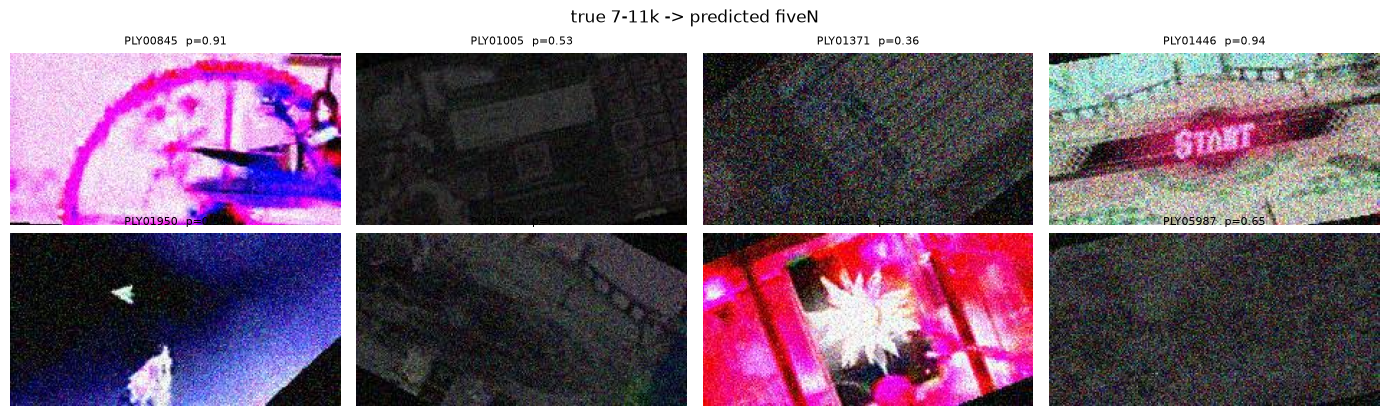

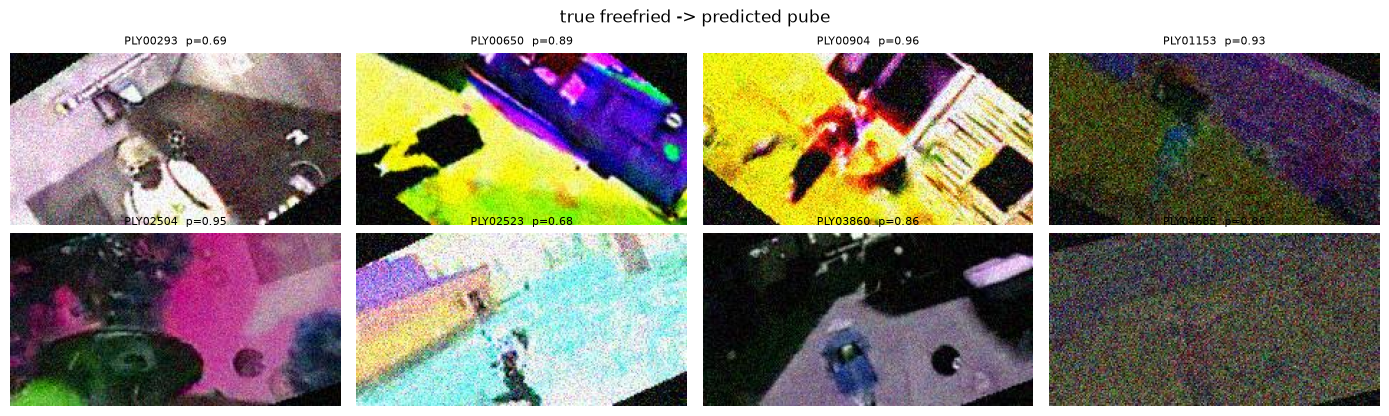

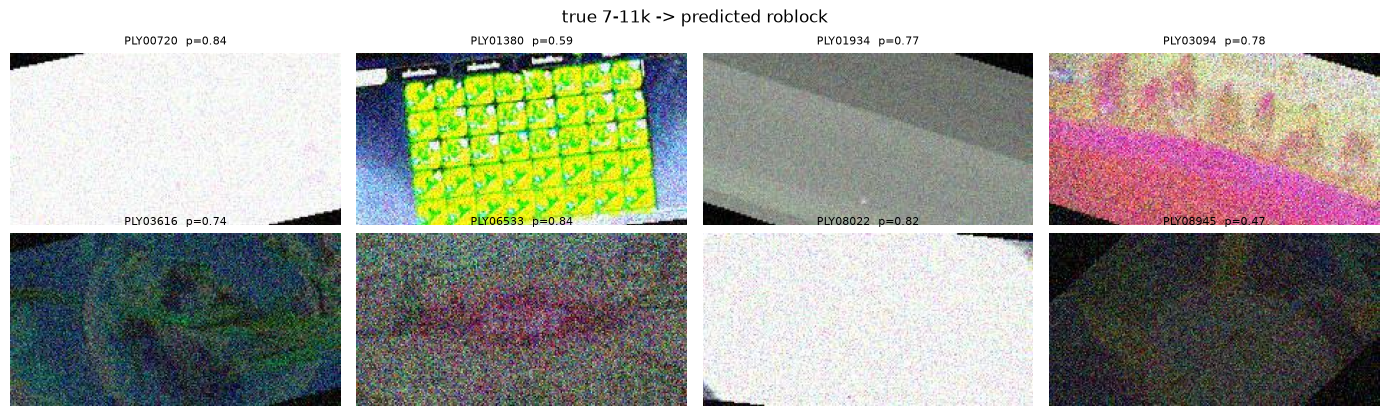

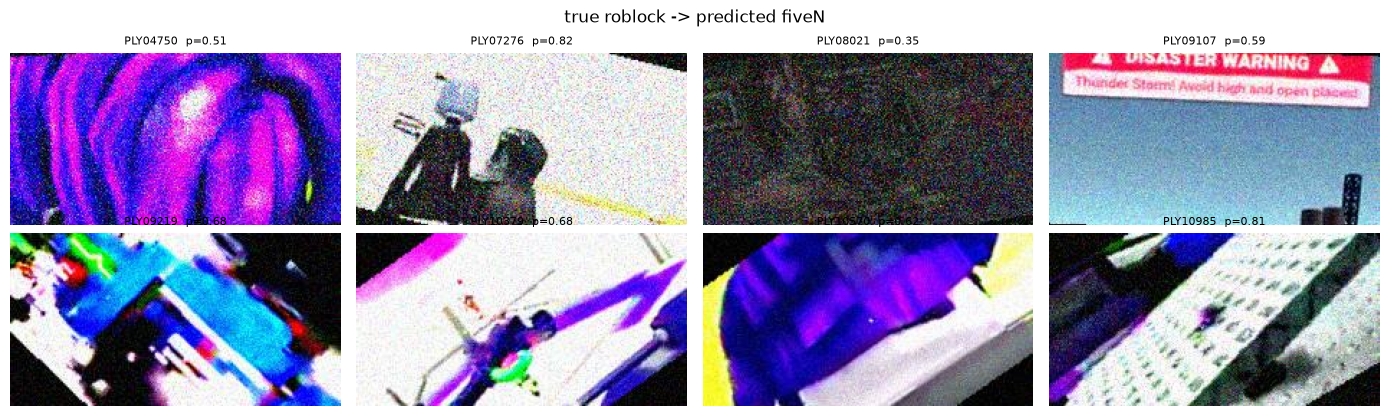

In [9]:
def show_mistakes(true_name: str, pred_name: str, n: int = 8):
    t, p = CLASS_NAMES.index(true_name), CLASS_NAMES.index(pred_name)
    rows = np.flatnonzero((valid_labels == t) & (plain_pred == p))[:n]
    if len(rows) == 0:
        print(true_name, "->", pred_name, ": none"); return
    fig, axes = plt.subplots(int(np.ceil(len(rows) / 4)), 4, figsize=(14, 2.1 * np.ceil(len(rows) / 4)), squeeze=False)
    for axis in axes.flat: axis.axis("off")
    for axis, r in zip(axes.flat, rows):
        with Image.open(valid_paths[r]) as image:
            axis.imshow(image.convert("RGB"))
        conf = probs["identity"][r, p]
        axis.set_title(f"{data.id.iat[valid_idx[r]]}  p={conf:.2f}", fontsize=8)
    fig.suptitle(f"true {true_name} -> predicted {pred_name}"); plt.tight_layout(); plt.show()

for _, m in mistakes.head(4).iterrows():
    show_mistakes(m["true"], m["pred"])

In [10]:
def image_stats(path):
    with Image.open(path) as image:
        gray = np.asarray(image.convert("L"), dtype=np.float32)
    return gray.mean(), laplace(gray).var()

stats = pd.DataFrame([image_stats(p) for p in valid_paths], columns=["brightness", "sharpness"])
stats["correct"] = plain_pred == valid_labels
stats["class"] = np.array(CLASS_NAMES)[valid_labels]
for col in ("brightness", "sharpness"):
    stats[f"{col}_bin"] = pd.qcut(stats[col], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"], duplicates="drop")
    print(f"\nAccuracy by {col} quartile:")
    print(stats.groupby(f"{col}_bin", observed=True).correct.agg(["size", "mean"]).round(4).to_string())
print("\nroblock accuracy by sharpness quartile:")
print(stats[stats["class"] == "roblock"].groupby("sharpness_bin", observed=True).correct.agg(["size", "mean"]).round(4).to_string())


Accuracy by brightness quartile:
                size    mean
brightness_bin              
Q1 low          1578  0.9379
Q2              1577  0.9639
Q3              1577  0.9708
Q4 high         1578  0.9639

Accuracy by sharpness quartile:
               size    mean
sharpness_bin              
Q1 low         1578  0.9658
Q2             1577  0.9601
Q3             1577  0.9575
Q4 high        1578  0.9531

roblock accuracy by sharpness quartile:
               size    mean
sharpness_bin              
Q1 low          180  0.9222
Q2              162  0.9321
Q3              149  0.9396
Q4 high         147  0.9456


## 5. Conclusions
Fill in after running:
- **TTA:** best combination, its gain over plain, and whether the gain is large enough to confirm on another fold and then apply to the full-data model (`t4_resnet18_geometry_full_v2` or a re-fit) for a new Task 4 column.
- **Near-duplicates:** estimated inflation of fold-1 macro F₁.
- **Errors:** the dominant confusion and whether brightness/sharpness explains it; any targeted fix it suggests.